# **Reading Data**

In [ ]:
import os,cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
import tensorflow.keras.backend as K
# from keras.utils import np_utils

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import cv2
import numpy as np


data_path = '/content/drive/MyDrive/Colorectal_tissue_dataset/Kather_texture_2016_image_tiles_5000'
data_dir_list = ['01_TUMOR', '02_STROMA', '03_COMPLEX', '04_LYMPHO', '05_DEBRIS', '06_MUCOSA', '07_ADIPOSE', '08_EMPTY']


folder_mapping = {
    '01_TUMOR': '0',
    '02_STROMA': '1',
    '03_COMPLEX': '2',
    '04_LYMPHO': '3',
    '05_DEBRIS': '4',
    '06_MUCOSA': '5',
    '07_ADIPOSE': '6',
    '08_EMPTY': '7'
}

img_data_list = []
labels = []

for dataset in data_dir_list:
    img_list = os.listdir(os.path.join(data_path, dataset))
    print('Loaded the images of dataset-{}\n'.format(folder_mapping[dataset]))
    for img in img_list:
        input_img = cv2.imread(os.path.join(data_path, dataset, img))
        labels.append(folder_mapping[dataset])
        input_img_resize = cv2.resize(input_img, (128, 128))
        img_data_list.append(input_img_resize)

label = np.array(labels)
data = np.array(img_data_list)

data = data.astype('float32')
data = data / 255.0

print("Data shape:", data.shape)

Loaded the images of dataset-0

Loaded the images of dataset-1

Loaded the images of dataset-2

Loaded the images of dataset-3

Loaded the images of dataset-4

Loaded the images of dataset-6

Loaded the images of dataset-7

Data shape: (5000, 128, 128, 3)


In [ ]:
num_classes = 8
from tensorflow.keras.utils import to_categorical
Y = to_categorical(label, num_classes)
x,y = shuffle(data,Y, random_state= 2)
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.1, random_state = 2)
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (4500, 128, 128, 3)
Shape of X_test: (500, 128, 128, 3)
Shape of y_train: (4500, 8)
Shape of y_test: (500, 8)


In [ ]:
X_train = X_train.reshape(-1,128,128, 3)
X_test = X_test.reshape(-1, 128, 128, 3)

# **Original Feature Distrubution**

In [ ]:
import numpy as np
import pandas as pd
x = X_test.reshape(500, -1)
np.savetxt('/content/drive/MyDrive/feature_files/ct_dataset_1_X_test.csv', x, delimiter = ",")

q =  np.argmax(y_test, axis =1).reshape(500, -1)
np.save('q.npy', q)
k = np.load('q.npy')
np.savetxt("/content/drive/MyDrive/feature_files/ct_dataset_1_y_test.csv", k,  delimiter = ",")

In [ ]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/feature_files/ct_dataset_1_X_test.csv", header = None, delimiter = ",")


In [ ]:
import numpy as np
from sklearn.manifold import TSNE
X = np.array(df)
X_embedded = TSNE(n_components=2).fit_transform(X)

In [ ]:
import pandas as pd
df1 = pd.read_csv("/content/drive/MyDrive/feature_files/ct_dataset_1_y_test.csv", header = None,  delimiter = ",")
df1.head()

,0
0,1.0
1,3.0
2,6.0
3,4.0
4,5.0


In [ ]:
import plotly.express as px
fig = px.scatter(X_embedded, x =0, y = 1, color=df1[0], width=600, height=500)
fig.show()

# **Reshaping the Data**

In [ ]:
X_train = X_train.reshape(-1, 128, 128, 3)
X_test = X_test.reshape(-1, 128, 128, 3)
X_train.shape

(4500, 128, 128, 3)

# **Network**

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import sys,os,cv2
import tensorflow as tf
from keras.layers import Conv2D, Add, MaxPooling2D, AveragePooling2D, Activation, Dense, PReLU, Layer
from keras.layers import Input, BatchNormalization, GlobalAveragePooling2D, Concatenate, Cropping2D, Multiply, Lambda, Flatten, Reshape
from keras.activations import relu, softmax, sigmoid, tanh
from keras import initializers
from keras.models import Model
from keras.regularizers import l2
import h5py

from sklearn.metrics import accuracy_score
from tensorflow import keras
from tensorflow.keras.utils import to_categorical
from keras.callbacks import ReduceLROnPlateau, ModelCheckpoint
from keras.models import load_model, Model

In [ ]:
# class DepthwiseSeparableConv2D(keras.layers.Layer):
#     def __init__(self, filters, kernel_size, padding, activation):
#         super(DepthwiseSeparableConv2D, self).__init__()
#         self.depthwise = DepthwiseConv2D(kernel_size = kernel_size, padding = padding, activation = activation)
#         self.pointwise = Conv2D(filters = filters, kernel_size = (1, 1), activation = activation)
#     def call(self, input_tensor):
#         x = self.depthwise(input_tensor)
#         return self.pointwise(x)

In [ ]:
def Cosin_similarity(input):
    dot1 = K.batch_dot(input[0], input[1], axes=[1, 1])
    dot2 = K.batch_dot(input[0], input[0], axes=[1, 1])
    dot3 = K.batch_dot(input[1], input[1], axes=[1, 1])
    max = K.maximum(K.sqrt(dot2 * dot3), K.epsilon())
    value = dot1 / max
    return K.tanh(value)

In [ ]:
def Bund(input):
    alpha_1 = input[0]
    alpha_2 = input[1]

    alpha_l = alpha_1/(alpha_1+alpha_2)
    alpha_g = alpha_2/(alpha_1+alpha_2)

    return alpha_l, alpha_g

In [ ]:
# import keras
# # from keras.applications import EfficientNetB0, ResNet50, VGG16, InceptionV3
# from keras.layers import Dense, GlobalAveragePooling2D, Conv2D, Flatten, Add, Activation, Input, MaxPooling2D, SeparableConv2D
# from tensorflow.keras.optimizers import RMSprop, Adam, Nadam
# from keras import regularizers
# from keras.models import Model
# def Enhance_Net(eps = 1.1e-5):
#     input1 = Input((19, 1024, 1))
#     x1 = SeparableConv2D(filters=32, kernel_size=(1, 3), padding = 'same', activation='relu')(input1)
#     x1 = BatchNormalization(axis=-1, epsilon=eps)(x1)
#     x2 = SeparableConv2D(filters=32, kernel_size=(1, 3), padding = 'same', activation='relu')(x1)
#     x2 = BatchNormalization(axis=-1, epsilon=eps)(x2)
#     x3 = SeparableConv2D(filters=32, kernel_size=(1, 3), padding = 'same', activation='relu')(x2)
#     x3 = BatchNormalization(axis=-1, epsilon=eps)(x3)
#     c1 = Concatenate()([x1, x2, x3])
#     c1 = SeparableConv2D(128, (1, 1), padding = 'same', activation = 'relu')(c1)
#     c1 = BatchNormalization(axis=-1, epsilon=eps)(c1)
#     c1 = MaxPooling2D(pool_size=(1, 2), strides=(1, 2), padding='same')(c1)

#     x11 = Conv2D(128, (1, 3), dilation_rate = 1, padding = 'same', activation = 'relu')(c1)
#     x11 = BatchNormalization(axis=-1, epsilon=eps)(x11)
#     x12 = Conv2D(128, (1, 3), dilation_rate = 2, padding = 'same', activation = 'relu')(c1)
#     x12 = BatchNormalization(axis=-1, epsilon=eps)(x12)
#     x13 = Conv2D(128, (1, 3), dilation_rate = 3, padding = 'same', activation = 'relu')(c1)
#     x13 = BatchNormalization(axis=-1, epsilon=eps)(x13)
#     M1 = Multiply()([x11, x12])
#     M2 = Multiply()([x11, x13])
#     M3 = Multiply()([x12, x13])
#     x21 = Conv2D(128, (1, 3), dilation_rate = 1, padding = 'same', activation = 'relu')(M1)
#     x21 = BatchNormalization(axis=-1, epsilon=eps)(x21)
#     x22 = Conv2D(128, (1, 3), dilation_rate = 2, padding = 'same', activation = 'relu')(M2)
#     x22 = BatchNormalization(axis=-1, epsilon=eps)(x22)
#     x23 = Conv2D(128, (1, 3), dilation_rate = 3, padding = 'same', activation = 'relu')(M3)
#     x23 = BatchNormalization(axis=-1, epsilon=eps)(x23)
#     M4 = Multiply()([x21, x22, x23])
#     x31 = Conv2D(128, (1,1), padding = 'same', activation = 'relu')(M4)
#     A1 = Add()([x31, c1])



#     x4 = SeparableConv2D(filters=64, kernel_size=(1, 3), padding = 'same', activation='relu')(x3)
#     x4 = BatchNormalization(axis=-1, epsilon=eps)(x4)
#     x5 = SeparableConv2D(filters=64, kernel_size=(1, 3), padding = 'same', activation='relu')(x4)
#     x5 = BatchNormalization(axis=-1, epsilon=eps)(x5)
#     c2 = Concatenate()([x4, x5])
#     c2 = SeparableConv2D(128, (1, 1), padding = 'same', activation = 'relu')(c2)
#     c2 = BatchNormalization(axis=-1, epsilon=eps)(c2)
#     c2 = MaxPooling2D(pool_size=(1, 2), strides=(1, 2), padding='same')(c2)

#     x41 = Conv2D(128, (1, 3), dilation_rate = 1, padding = 'same', activation = 'relu')(c2)
#     x41 = BatchNormalization(axis=-1, epsilon=eps)(x41)
#     x42 = Conv2D(128, (1, 3), dilation_rate = 2, padding = 'same', activation = 'relu')(c2)
#     x42 = BatchNormalization(axis=-1, epsilon=eps)(x42)
#     x43 = Conv2D(128, (1, 3), dilation_rate = 3, padding = 'same', activation = 'relu')(c2)
#     x43 = BatchNormalization(axis=-1, epsilon=eps)(x43)
#     M5 = Multiply()([x41, x42])
#     M6 = Multiply()([x41, x43])
#     M7 = Multiply()([x42, x43])
#     x51 = Conv2D(128, (1, 3), dilation_rate = 1, padding = 'same', activation = 'relu')(M5)
#     x51 = BatchNormalization(axis=-1, epsilon=eps)(x51)
#     x52 = Conv2D(128, (1, 3), dilation_rate = 2, padding = 'same', activation = 'relu')(M6)
#     x52 = BatchNormalization(axis=-1, epsilon=eps)(x52)
#     x53 = Conv2D(128, (1, 3), dilation_rate = 3, padding = 'same', activation = 'relu')(M7)
#     x53 = BatchNormalization(axis=-1, epsilon=eps)(x53)
#     M8 = Multiply()([x51, x52, x53])
#     x61 = Conv2D(128, (1,1), padding = 'same', activation = 'relu')(M8)
#     A2 = Add()([x61, c2])

#     x_lg = Multiply()([A1, A2])
#     x_gl = Add()([A1, A2])
#     x_c = Concatenate()([x_lg, x_gl])

#     x_c = GlobalAveragePooling2D()(x_c)
#     x_l = GlobalAveragePooling2D()(A1)
#     x_g = GlobalAveragePooling2D()(A2)

#     x_l = Dense(units= 256, activation=relu)(x_l)
#     x_g = Dense(units= 256, activation=relu)(x_g)
#     share_1 = Dense(units=512, activation=relu)
#     share_2 = Dense(units=512, activation=relu)
#     x_l = share_1(x_l)
#     x_g = share_1(x_g)
#     x_c = share_1(x_c)
#     x_l = share_2(x_l)
#     x_g = share_2(x_g)
#     x_c = share_2(x_c)

#     alpha_1 = Lambda(Cosin_similarity)([x_l, x_c])
#     alpha_2 = Lambda(Cosin_similarity)([x_c, x_c])
#     alpha_l, alpha_g = Lambda(Bund)([alpha_1, alpha_2])
#     out_l = Multiply()([alpha_l, x_l])
#     out_g = Multiply()([alpha_g, x_c])

#     out = Concatenate()([out_l, out_g])
#     out = Dense(units=2, activation= 'sigmoid')(out)
#     model = Model([input1], [out])
#     return model

# model = Enhance_Net(eps = 1.1e-5)
# opt = Nadam(learning_rate=0.0001)
# model.compile(optimizer=opt, loss=['categorical_crossentropy'], metrics=['acc'])
# model.summary()

In [ ]:
#spatial attention
def residual_csa_module(input_tensor, reduction_ratio=16):
    channels = input_tensor.shape[-1]

    # Convolutional layer for feature extraction
    conv1 = Conv2D(filters=channels // reduction_ratio, kernel_size=(1, 1), padding='same', activation='relu')(input_tensor)
    conv2 = Conv2D(filters=channels // reduction_ratio, kernel_size=(1, 1), padding='same', activation='relu')(conv1)
    conv3 = Conv2D(filters=channels, kernel_size=(1, 1), padding='same', activation='relu')(conv2)

    # Spatial attention mechanism
    attention_map = Conv2D(filters=1, kernel_size=(1, 1), padding='same', activation='sigmoid')(conv3)

    # Multiply attention map with input tensor
    attention = Multiply()([attention_map, input_tensor])

    # Residual connection
    output = Add()([attention, input_tensor])

    return output

In [ ]:
#channel attention
def eca_module(input_tensor, gamma=2, b=1):
    channels = input_tensor.shape[-1]
    print(channels)

    squeeze = GlobalAveragePooling2D()(input_tensor)
    excitation = Dense(units=channels // gamma)(squeeze)
    excitation = Activation('relu')(excitation)
    excitation = Dense(units=channels)(excitation)
    excitation = Activation('sigmoid')(excitation)
    excitation = Reshape((1, 1, channels))(excitation)

    scale = Multiply()([input_tensor, excitation])

    output = Add()([scale, input_tensor])
    return output

In [ ]:
from keras.models import Model
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.optimizers import RMSprop, Adam, Nadam
from keras.layers import Input, Conv2D, LSTM, Add, Multiply, Concatenate, MaxPooling2D, AveragePooling2D, Flatten, Lambda
from keras.layers import SeparableConv2D, MaxPooling2D, Flatten, Dense, GlobalAveragePooling2D, GlobalMaxPooling2D, BatchNormalization
eps = 1.1e-5
input1 = Input((128, 128, 3))

x1 = Conv2D(64, (3, 3), padding = 'same', activation='relu')(input1)
x1 = BatchNormalization(axis=-1, epsilon=eps)(x1)
x2 = Conv2D(64, (3, 3), padding = 'same', activation='relu')(x1)
x2 = BatchNormalization(axis=-1, epsilon=eps)(x2)
x3 = Conv2D(64, (3, 3), padding = 'same', activation='relu')(x2)
x3 = BatchNormalization(axis=-1, epsilon=eps)(x3)
c1 = Concatenate()([x1, x2, x3])

x11 = Conv2D(192, (3,3), dilation_rate = (1, 1), padding = 'same', activation='relu')(c1)
x11 = BatchNormalization(axis=-1, epsilon=eps)(x11)
x21 = Conv2D(192, (3,3), dilation_rate = (2, 2), padding = 'same', activation='relu')(c1)
x21 = BatchNormalization(axis=-1, epsilon=eps)(x21)
x31 = Conv2D(192, (3,3), dilation_rate = (3, 3) , padding = 'same', activation='relu')(c1)
x31 = BatchNormalization(axis=-1, epsilon=eps)(x31)
M1 = Multiply()([x11, x21])
M2 = Multiply()([x11, x31])
M3 = Multiply()([x21, x31])
x111 = Conv2D(192, (3,3),dilation_rate = (1, 1), padding = 'same', activation='relu')(M1)
x111 = BatchNormalization(axis=-1, epsilon=eps)(x111)
x211 = Conv2D(192, (3,3),dilation_rate = (2, 2), padding = 'same', activation='relu')(M2)
x211 = BatchNormalization(axis=-1, epsilon=eps)(x211)
x311 = Conv2D(192, (3,3),dilation_rate = (3, 3), padding = 'same', activation='relu')(M3)
x311 = BatchNormalization(axis=-1, epsilon=eps)(x311)
M4 = Multiply()([x111, x211, x311])
X44 = Conv2D(192, (1,1), padding = 'same', activation='relu')(M4)
X44 = BatchNormalization(axis=-1, epsilon=eps)(X44)
A1 = Add()([X44, c1])

#spatial attention
res_csa_module1 = residual_csa_module(A1)

x4 = Conv2D(64, (3, 3), padding = 'same', activation='relu')(x3)
x4 = BatchNormalization(axis=-1, epsilon=eps)(x4)
x5 = Conv2D(64, (3, 3), padding = 'same', activation='relu')(x4)
x5 = BatchNormalization(axis=-1, epsilon=eps)(x5)
x6 = Conv2D(64, (3, 3), padding = 'same', activation='relu')(x5)
x6 = BatchNormalization(axis=-1, epsilon=eps)(x6)
c2 = Concatenate()([x4, x5, x6])

x51 = Conv2D(192, (3,3), dilation_rate = (1, 1), padding = 'same', activation='relu')(c2)
x51 = BatchNormalization(axis=-1, epsilon=eps)(x51)
x61 = Conv2D(192, (3,3),dilation_rate = (2, 2), padding = 'same', activation='relu')(c2)
x61 = BatchNormalization(axis=-1, epsilon=eps)(x61)
x71 = Conv2D(192, (3,3),dilation_rate = (3, 3), padding = 'same', activation='relu')(c2)
x71 = BatchNormalization(axis=-1, epsilon=eps)(x71)
M6 = Multiply()([x51, x61])
M7 = Multiply()([x51, x71])
M8 = Multiply()([x61, x71])
x511 = Conv2D(192, (3,3), dilation_rate = (1, 1), padding = 'same', activation='relu')(M6)
x511 = BatchNormalization(axis=-1, epsilon=eps)(x511)
x611 = Conv2D(192, (3,3),dilation_rate = (2, 2), padding = 'same', activation='relu')(M7)
x611 = BatchNormalization(axis=-1, epsilon=eps)(x611)
x711 = Conv2D(192, (3,3), dilation_rate = (3, 3),padding = 'same', activation='relu')(M8)
x711 = BatchNormalization(axis=-1, epsilon=eps)(x711)
M9 = Multiply()([x511, x611, x711])
X81 = Conv2D(192, (1,1), padding = 'same', activation='relu')(M9)
X81 = BatchNormalization(axis=-1, epsilon=eps)(X81)
A2 = Add()([X81, c2])

#channel attention
eca_module1 = eca_module(A2)

x_l = A1
x_g = A2

# x_lg = Multiply()([A1, A2])
# x_gl = Add()([A1, A2])
x_c = Concatenate()([x_l, x_g])

x_l = GlobalAveragePooling2D()(x_l)
x_g = GlobalAveragePooling2D()(x_g)
x_c = GlobalAveragePooling2D()(x_c)

x_l = Dense(units=384, activation='relu')(x_l)
x_g = Dense(units=384, activation='relu')(x_g)

share_1 = Dense(units=768, activation='relu')
share_2 = Dense(units=768, activation='relu')

x_l = share_1(x_l)
x_g = share_1(x_g)
x_c = share_1(x_c)

x_l = share_2(x_l)
x_g = share_2(x_g)
x_c = share_2(x_c)

alpha_1 = Lambda(Cosin_similarity, output_shape= (None, 1))([x_l, x_c])
alpha_2 = Lambda(Cosin_similarity, output_shape= (None, 1))([x_g, x_c])
alpha_l, alpha_g = Lambda(Bund)([alpha_1, alpha_2])
out_l = Multiply()([alpha_l, x_l])
out_g = Multiply()([alpha_g, x_g])

out = Concatenate()([out_l, out_g])
out = Dense(units = 64, activation = 'relu')(out)

out = Dense(units=8, activation="softmax")(out)
model = Model(inputs=input1, outputs=out)
opt = Nadam(learning_rate=0.0001)
model.compile(optimizer= opt, loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

192
Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 128, 128, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 128, 128, 64)         1792      ['input_1[0][0]']             
                                                                                                  
 batch_normalization (Batch  (None, 128, 128, 64)         256       ['conv2d[0][0]']              
 Normalization)                                                                                   
                                                                                                  
 conv2d_1 (Conv2D)           (None, 128, 128, 64)         36928     ['batch_normalization[

# **Training Model**

In [ ]:
# model.compile(optimizer= Adam(learning_rate=0.0001, weight_decay = 1e-5), loss='categorical_crossentropy', metrics=['accuracy'])
from keras.callbacks import EarlyStopping, ModelCheckpoint
early_stopping = EarlyStopping(
                              patience=10,
                              min_delta=0.001,
                              monitor="val_accuracy",
                              restore_best_weights=True
                              )
# Define the model checkpoint callback to save the best weights
checkpoint = ModelCheckpoint('/content/drive/MyDrive/weight_files/Dataset_1'+'-{epoch:02d}.h5', monitor='val_accuracy', save_best_only=True)

history = model.fit(X_train, y_train, batch_size= 16, epochs= 50,
                    verbose=1, callbacks=[early_stopping, checkpoint], validation_data=(X_test, y_test), shuffle = True) #, callbacks=[early_stopping, checkpoint]

Epoch 1/50
282/282 [==============================] - 518s 2s/step - loss: 0.9838 - accuracy: 0.6260 - val_loss: 3.7001 - val_accuracy: 0.1020
Epoch 2/50
282/282 [==============================] - 465s 2s/step - loss: 0.5692 - accuracy: 0.7880 - val_loss: 2.6626 - val_accuracy: 0.2700
Epoch 3/50
282/282 [==============================] - 469s 2s/step - loss: 0.4481 - accuracy: 0.8393 - val_loss: 1.7200 - val_accuracy: 0.5840
Epoch 4/50
282/282 [==============================] - 469s 2s/step - loss: 0.3989 - accuracy: 0.8580 - val_loss: 0.4625 - val_accuracy: 0.8480
Epoch 5/50
282/282 [==============================] - 464s 2s/step - loss: 0.3582 - accuracy: 0.8762 - val_loss: 0.2497 - val_accuracy: 0.9200
Epoch 6/50
282/282 [==============================] - 468s 2s/step - loss: 0.3105 - accuracy: 0.8931 - val_loss: 3.8675 - val_accuracy: 0.6660
Epoch 7/50
282/282 [==============================] - 468s 2s/step - loss: 0.2929 - accuracy: 0.8996 - val_loss: 0.2317 - val_accuracy: 0.9180

# **Loading & Saving the Training Model**

In [ ]:
import keras
from keras import backend as K

# Define the custom Cosin_similarity function
def Cosin_similarity(inputs):
    dot1 = K.batch_dot(inputs[0], inputs[1], axes=[1, 1])
    dot2 = K.batch_dot(inputs[0], inputs[0], axes=[1, 1])
    dot3 = K.batch_dot(inputs[1], inputs[1], axes=[1, 1])
    max_val = K.maximum(K.sqrt(dot2 * dot3), K.epsilon())
    value = dot1 / max_val
    return K.tanh(value)

# Load the model with custom objects
custom_objects = {'Cosin_similarity': Cosin_similarity}

model = keras.models.load_model('/content/drive/MyDrive/weight_files/Dataset_1-17.keras', custom_objects=custom_objects, safe_mode=False)

# Save the complete model (architecture + weights)
# model.save('/content/drive/MyDrive/weight_files/ct1_model.h5')


In [ ]:
# import keras
# model = keras.models.load_model('/content/drive/MyDrive/weight_files/Dataset_1-17.keras', safe_mode=False)

# model.save('/content/drive/MyDrive/weight_files/ct1_model.keras')

In [ ]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 128, 128, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 128, 128, 64)         1792      ['input_1[0][0]']             
                                                                                                  
 batch_normalization (Batch  (None, 128, 128, 64)         256       ['conv2d[0][0]']              
 Normalization)                                                                                   
                                                                                                  
 conv2d_1 (Conv2D)           (None, 128, 128, 64)         36928     ['batch_normalization[0][0

# **Model Prediction**

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# Predicting the Test set results
pred = model.predict(X_test)
print("Y_pred:", pred)
print("*****************")
y_pred = np.argmax(pred, axis = 1)
y_true = np.argmax(y_test, axis = 1)

16/16 [==============================] - 1409s 88s/step - loss: 0.2004 - accuracy: 0.9500
Test Loss: 0.2003745287656784
Test Accuracy: 0.949999988079071
16/16 [==============================] - 1360s 85s/step
Y_pred: [[1.4350272e-05 9.9990016e-01 8.2243336e-05 ... 3.2404284e-07
  8.2396188e-09 3.6285140e-08]
 [8.2079328e-05 8.7288413e-08 9.5423811e-06 ... 7.6468814e-06
  2.6105548e-07 2.1607529e-07]
 [6.9557625e-04 2.1926744e-03 2.7606660e-04 ... 5.0410809e-04
  9.7476691e-01 1.1338848e-02]
 ...
 [3.2561284e-06 9.9974436e-01 2.0063468e-04 ... 7.1504115e-07
  8.4765375e-08 1.9440402e-07]
 [9.0806233e-04 1.2312440e-03 1.4204140e-03 ... 1.3960400e-04
  1.9902468e-01 7.9443592e-01]
 [4.3068800e-04 1.1827751e-03 1.9460268e-04 ... 9.8191987e-05
  9.8125905e-01 1.3255862e-02]]
*****************


# **Confusion Matrix**

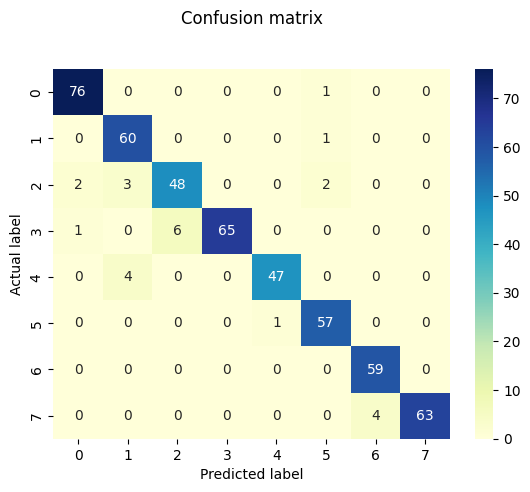

In [ ]:
#Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)
target_names = ['0', '1', '2', '3', '4', '5', '6', '7']
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
p = sns.heatmap(pd.DataFrame(cm), annot=True,xticklabels=target_names, yticklabels=target_names, cmap="YlGnBu" ,fmt='g')
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.savefig('/content/drive/MyDrive/pdfs/ct1_Task_CM.pdf')

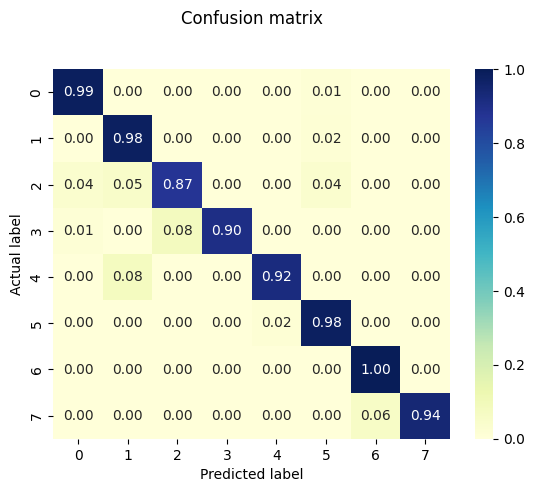

In [ ]:
#Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)
target_names = ['0', '1', '2', '3', '4', '5', '6', '7']
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
cm = cm.astype('float')/cm.sum(axis=1)[:, np.newaxis]
p = sns.heatmap(pd.DataFrame(cm), annot=True,xticklabels=target_names, yticklabels=target_names, cmap="YlGnBu" ,fmt='.2f')
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.savefig('/content/drive/MyDrive/pdfs/ct1_Task_NCM.pdf')

# **Classification Report**

In [ ]:
#import classification_report
from sklearn.metrics import classification_report
print(classification_report(y_true,y_pred, target_names = target_names))

              precision    recall  f1-score   support

           0       0.96      0.99      0.97        77
           1       0.90      0.98      0.94        61
           2       0.89      0.87      0.88        55
           3       1.00      0.90      0.95        72
           4       0.98      0.92      0.95        51
           5       0.93      0.98      0.96        58
           6       0.94      1.00      0.97        59
           7       1.00      0.94      0.97        67

    accuracy                           0.95       500
   macro avg       0.95      0.95      0.95       500
weighted avg       0.95      0.95      0.95       500



# **ROC Curve**

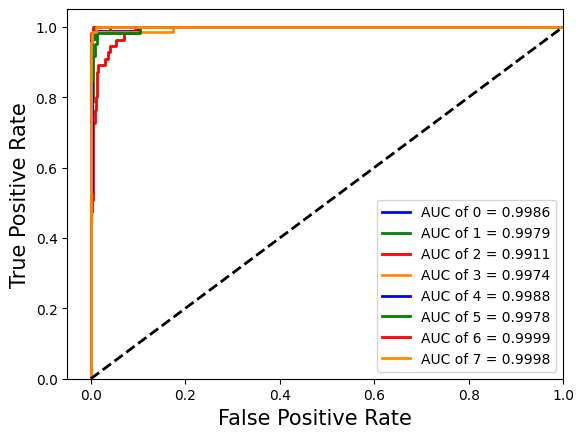

In [ ]:
from sklearn.metrics import roc_curve, auc
from itertools import cycle
fpr = dict()
tpr = dict()
roc_auc = dict()
lw=2
for i in range(8):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
colors =cycle(['blue', 'green', 'red','darkorange'])
for i, color in zip(range(8), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='AUC of {0} = {1:0.4f}'
             ''.format(i, roc_auc[i]))
plt.plot([0, 1], [0, 1], 'k--', lw=lw)
plt.xlim([-0.05, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate',fontsize=15)
plt.ylabel('True Positive Rate',fontsize=15)
# plt.title('Receiver operating characteristic for multi-class data')
plt.legend(loc="lower right")
plt.savefig('/content/drive/MyDrive/pdfs/ct1_Task_ROC.pdf')
plt.show()

In [ ]:
np.save('/content/drive/MyDrive/fpr-tpr_files/ct1_fpr_task.npy', fpr)
np.save('/content/drive/MyDrive/fpr-tpr_files/ct1_tpr_task.npy', tpr)

# **Model Size, FLOPS, and MACS**

In [ ]:
import tensorflow as tf
from tensorflow import keras

# Calculate FLOPs and MACs
flops = 0
macs = 0

for layer in model.layers:
    if isinstance(layer, keras.layers.Conv2D):
        # Get layer parameters
        filters = layer.filters
        kernel_size = layer.kernel_size
        strides = layer.strides
        input_shape = layer.input_shape[1:]

        # Calculate FLOPs
        flops += 2 * np.prod(input_shape) * filters * np.prod(kernel_size) / np.prod(strides)

        # Calculate MACs
        macs += np.prod(input_shape) * filters * np.prod(kernel_size) / np.prod(strides)

    elif isinstance(layer, keras.layers.Dense):
        # Get layer parameters
        units = layer.units
        input_shape = layer.input_shape[1:]

        # Calculate FLOPs
        flops += 2 * np.prod(input_shape) * units

        # Calculate MACs
        macs += np.prod(input_shape) * units

print("FLOPs:", flops)
print("MACs:", macs)
# Convert FLOPs to GFLOPs
flops_in_giga = flops / 1e9

# Convert MACs to GMACs
macs_in_giga = macs / 1e9

print("GFLOPs:", flops_in_giga)
print("GMACs:", macs_in_giga)

FLOPs: 138974233600.0
MACs: 69487116800.0
GFLOPs: 138.9742336
GMACs: 69.4871168


In [ ]:
# Calculate model size in MB
model_size = model.count_params() * 4 / (1024 * 1024)  # Assuming float32 precision
print("Model Size (MB):", model_size)

Model Size (MB): 20.560577392578125


# **Trained Feature Visualization**

In [ ]:
from keras.models import Model
model = model
layer_name = 'dense_6'
intermediate_layer_model = Model(inputs = model.input, outputs = model.get_layer(layer_name).output)
intermediate_output1 = intermediate_layer_model.predict([X_test])

16/16 [==============================] - 1767s 108s/step


In [ ]:
import numpy as np
import pandas as pd
np.savetxt("/content/drive/MyDrive/feature_files/ct_dataset_1_X_test_Proposed_Features.csv", intermediate_output1, delimiter = ",")

In [ ]:
df2 = pd.read_csv("/content/drive/MyDrive/feature_files/ct_dataset_1_X_test_Proposed_Features.csv", header = None, delimiter = ",")
df2

,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
0,3.191668,0.0,0.0,3.124542,0.000000,2.169495,0.486898,4.957413,0.0,1.059627,...,4.493810,1.081906,3.732867,0.0,3.556253,3.558847,0.000000,0.0,0.000000,0.863351
1,2.144109,0.0,0.0,0.000000,0.000000,3.407605,1.377989,0.000000,0.0,0.000000,...,6.155706,0.000000,3.683265,0.0,0.000000,1.266021,0.000000,0.0,0.000000,6.053806
2,0.334616,0.0,0.0,0.112923,0.859823,3.300594,1.250365,0.205856,0.0,0.000000,...,1.473841,2.384728,0.129332,0.0,0.100587,0.004923,1.725587,0.0,1.436948,1.351931
3,2.431031,0.0,0.0,0.000000,0.000000,0.434311,0.000000,1.381122,0.0,0.100224,...,2.790261,2.971953,0.050396,0.0,1.705337,0.901677,0.581984,0.0,0.398706,0.000000
4,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,3.395054,0.0,0.000000,...,7.461071,2.368001,1.619735,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,0.000000,0.0,0.0,0.000000,0.000000,2.328484,0.000000,2.776404,0.0,0.000000,...,6.221067,0.000000,2.351867,0.0,0.000000,0.717721,0.000000,0.0,0.000000,3.026261
496,0.580646,0.0,0.0,0.245837,0.841254,3.166437,1.334988,0.357399,0.0,0.006729,...,1.424089,2.330957,0.040012,0.0,0.303464,0.200537,1.591303,0.0,1.347163,1.394573
497,3.425027,0.0,0.0,2.481388,0.000000,2.709935,0.000000,3.654473,0.0,0.000000,...,4.571527,1.824270,3.639721,0.0,3.182751,3.346326,0.000000,0.0,0.000000,0.639713
498,0.052513,0.0,0.0,0.765159,1.988591,3.216737,2.445553,0.000000,0.0,0.000000,...,0.265476,0.308618,0.000000,0.0,0.000000,0.232568,0.536428,0.0,1.126907,2.805339


In [ ]:
import numpy as np
from sklearn.manifold import TSNE
X = np.array(df2)
X_embedded = TSNE(n_components=2).fit_transform(X)

In [ ]:
df3 = pd.read_csv("/content/drive/MyDrive/feature_files/ct_dataset_1_y_test.csv", header = None,  delimiter = ",")
df3.head()

,0
0,1.0
1,3.0
2,6.0
3,4.0
4,5.0


In [ ]:
import plotly.express as px
fig = px.scatter(X_embedded, x =0, y = 1, color=df3[0], width=600, height=500)
fig.show()


### **PLots**

---



### **Radar Spider Chart**

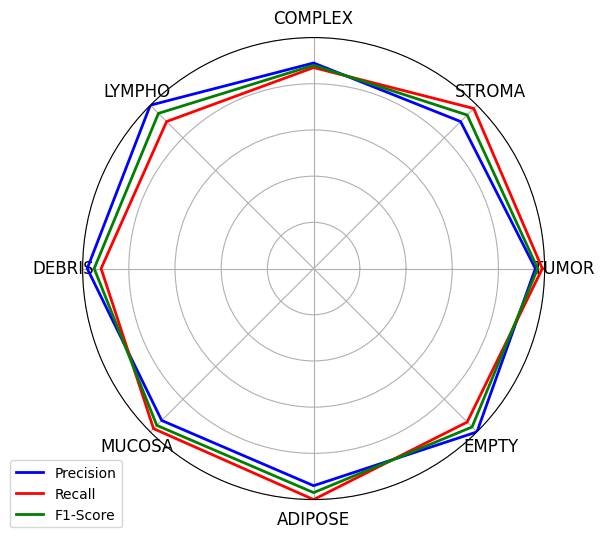

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi

# Define the metrics and their values
labels = ['TUMOR', 'STROMA', 'COMPLEX', 'LYMPHO', 'DEBRIS', 'MUCOSA', 'ADIPOSE', 'EMPTY']
precision = [0.96, 0.90, 0.89, 1.00, 0.98, 0.93, 0.94, 1.00]
recall = [0.99, 0.98, 0.87, 0.90, 0.92, 0.98, 1.00, 0.94]
f1_score = [0.97, 0.94, 0.88, 0.95, 0.95, 0.96, 0.97, 0.97]

# Combine metrics into a single list of lists
metrics = [precision, recall, f1_score]
metrics_labels = ['Precision', 'Recall', 'F1-Score']
colors = ['b', 'r', 'g']  # Colors for each metric

# Number of variables
num_vars = len(labels)

# Compute angle of each axis
angles = [n / float(num_vars) * 2 * pi for n in range(num_vars)]
angles += angles[:1]  # Repeat the first angle to close the circle

# Initialize the radar chart
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

# Set face color to transparent
ax.set_facecolor('none')

# Draw one axe per variable and add labels
plt.xticks(angles[:-1], labels, size=12)

# Draw y-labels
ax.set_yticklabels([])  # Remove the numeric values
ax.set_ylim(0.0, 1.0)

# Plot data
for metric, label, color in zip(metrics, metrics_labels, colors):
    values = metric + metric[:1]
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=label, color=color)

# Add a legend
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))

# Save the plot as a PDF
plt.savefig("/content/drive/MyDrive/pdfs/ct_1_cnn_metrics_radar_chart.pdf", facecolor='none', transparent=True)

# Show the plot
plt.show()


dataset 2

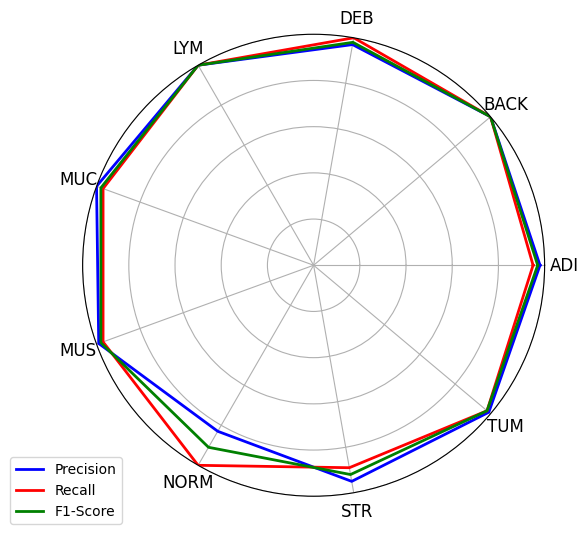

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi

# Define the metrics and their values
labels = ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']
precision = [0.98, 1.00, 0.97, 1.00, 1.00, 0.99, 0.83, 0.95, 0.99]
recall = [0.95, 1.00, 1.00, 1.00, 0.97, 0.97, 1.00, 0.89, 0.98]
f1_score = [0.97, 1.00, 0.98, 1.00, 0.98, 0.98, 0.91, 0.92, 0.98]

# Combine metrics into a single list of lists
metrics = [precision, recall, f1_score]
metrics_labels = ['Precision', 'Recall', 'F1-Score']
colors = ['b', 'r', 'g']  # Colors for each metric

# Number of variables
num_vars = len(labels)

# Compute angle of each axis
angles = [n / float(num_vars) * 2 * pi for n in range(num_vars)]
angles += angles[:1]  # Repeat the first angle to close the circle

# Initialize the radar chart
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

# Set face color to transparent
ax.set_facecolor('none')

# Draw one axe per variable and add labels
plt.xticks(angles[:-1], labels, size=12)

# Draw y-labels
ax.set_yticklabels([])  # Remove the numeric values
ax.set_ylim(0.0, 1.0)

# Plot data
for metric, label, color in zip(metrics, metrics_labels, colors):
    values = metric + metric[:1]
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=label, color=color)

# Add a legend
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))

# Save the plot as a PDF
plt.savefig("/content/drive/MyDrive/pdfs/ct_2_cnn_metrics_radar_chart.pdf", facecolor='none', transparent=True)

# Show the plot
plt.show()


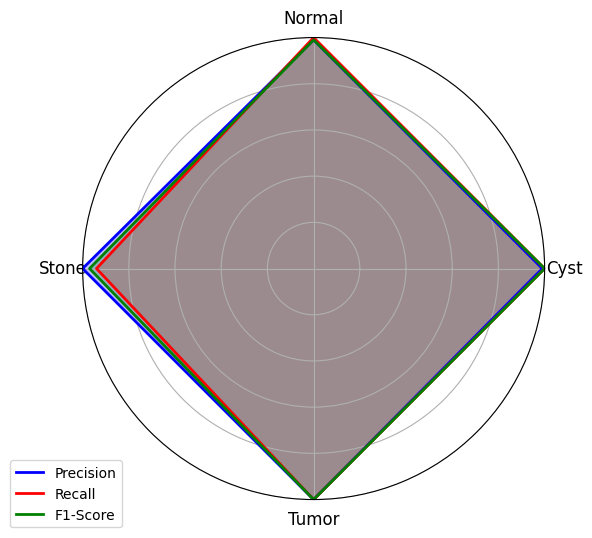

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi

# Define the metrics and their values
labels = ['Cyst', 'Normal', 'Stone', 'Tumor']
precision = [0.99, 0.99, 1.00, 1.00]
recall = [1.00, 1.00, 0.94, 1.00]
f1_score = [1.00, 0.99, 0.97, 1.00]

# Combine metrics into a single list of lists
metrics = [precision, recall, f1_score]
metrics_labels = ['Precision', 'Recall', 'F1-Score']
colors = ['b', 'r', 'g']  # Colors for each metric

# Number of variables
num_vars = len(labels)

# Compute angle of each axis
angles = [n / float(num_vars) * 2 * pi for n in range(num_vars)]
angles += angles[:1]  # Repeat the first angle to close the circle

# Initialize the radar chart
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

# Set face color to transparent
ax.set_facecolor('none')

# Draw one axe per variable and add labels
plt.xticks(angles[:-1], labels, size=12)

# Draw y-labels
ax.set_yticklabels([])  # Remove the numeric values
ax.set_ylim(0.0, 1.0)

# Plot data
for metric, label, color in zip(metrics, metrics_labels, colors):
    values = metric + metric[:1]
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=label, color=color)
    ax.fill(angles, values, color=color, alpha=0.25)

# Add a legend
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))

# Save the plot as a PDF
plt.savefig("/content/drive/MyDrive/pdfs/kidney_radar_chart.pdf", facecolor='none', transparent=True)

# Show the plot
plt.show()
